# Import

In [1]:
%reset -f
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import meshio
from time import time
import sys
sys.path.append('../')

from sources.parameters import *
from sources.data import *
from sources.model import *
from sources.solver import *

# make data

In [2]:
gen = data_generator(ub,lb)

In [3]:
X_r, X_data, u_data = gen.gen_train_data(10_000_000,5_000,5_000)

In [4]:
X_data, u_data = gen.add_data([400, 450, 500, 550, 600, 650, 700, 750, 801, 850, 900, 951, 1001])
X_data, u_data

([<tf.Tensor: shape=(3037, 3), dtype=float32, numpy=
  array([[ 0.       , -3.       ,  3.       ],
         [ 0.       , -2.8      ,  3.       ],
         [ 0.       , -2.8783321,  2.8693693],
         ...,
         [ 0.       ,  2.8520296, -2.8595142],
         [ 0.       ,  2.8      , -3.       ],
         [ 0.       ,  3.       , -3.       ]], dtype=float32)>,
  <tf.Tensor: shape=(3037, 3), dtype=float32, numpy=
  array([[ 0.5      , -3.       ,  3.       ],
         [ 0.5      , -2.8      ,  3.       ],
         [ 0.5      , -2.8782728,  2.8693016],
         ...,
         [ 0.5      ,  2.851963 , -2.8594484],
         [ 0.5      ,  2.8      , -3.       ],
         [ 0.5      ,  3.       , -3.       ]], dtype=float32)>,
  <tf.Tensor: shape=(3041, 3), dtype=float32, numpy=
  array([[ 1.       , -3.       ,  3.       ],
         [ 1.       , -2.8      ,  3.       ],
         [ 1.       , -2.8782563,  2.8692815],
         ...,
         [ 1.       ,  2.8518896, -2.8593757],
         [ 

# training

In [5]:
from time import time

model_hydro = PhysicsInformedNN(lb, ub, output_dim=2, num_hidden_layers=8, num_neurons_per_layer=256, activation='relu')
model_magneto = PhysicsInformedNN(lb, ub, output_dim=2, num_hidden_layers=8, num_neurons_per_layer=256, activation='tanh')


In [6]:

solver = vincisolver2(model_hydro, model_magneto, batch_size = 3_000)

lr_1 = tf.keras.optimizers.schedules.ExponentialDecay(
    1e-3,
    decay_steps=200,
    decay_rate=0.98,
    staircase=True)

lr_2 = tf.keras.optimizers.schedules.ExponentialDecay(
    1e-3,
    decay_steps=200,
    decay_rate=0.98,
    staircase=True)

optim_1 = tf.keras.optimizers.Adam(learning_rate=lr_1)
optim_2 = tf.keras.optimizers.Adam(learning_rate=lr_2)    

t0 = time()
try: 
    solver.solve(optim_1, optim_2, X_r, X_data, u_data)
except:
  pass

print('\nTraining time: {} seconds'.format(time()-t0))

Epoch 00_000: 

                    phi_r1       9.2265e-03  
                    phi_r2       9.2095e-05
                    phi_r3       2.8209e-03
                    phi_r4       3.9689e+00
                    phi_0_omega  1.3096e+02
                    phi_0_phi    1.4798e-01
                    phi_0_J      2.3123e+03
                    phi_0_psi    5.4039e+01
                    total_loss   2.5014e+03

Training time: 11.394083499908447 seconds


<AxesSubplot:xlabel='Iteration', ylabel='Loss'>

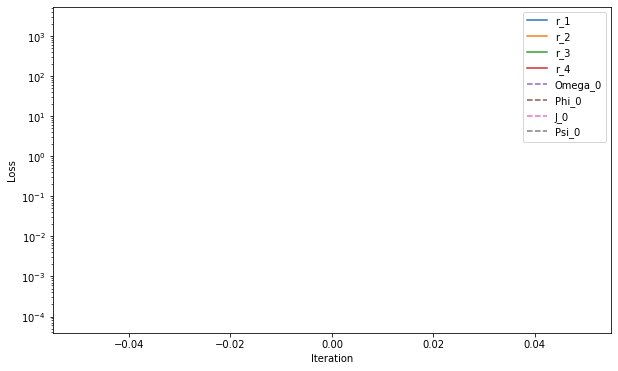

In [7]:
solver.plot_loss_history()

In [8]:
model_hydro.load_weights(WEIGHT_PATH + 'knotfest_hydro.h5')
model_magneto.load_weights(WEIGHT_PATH + 'knotfest_magneto.h5')

# Check results

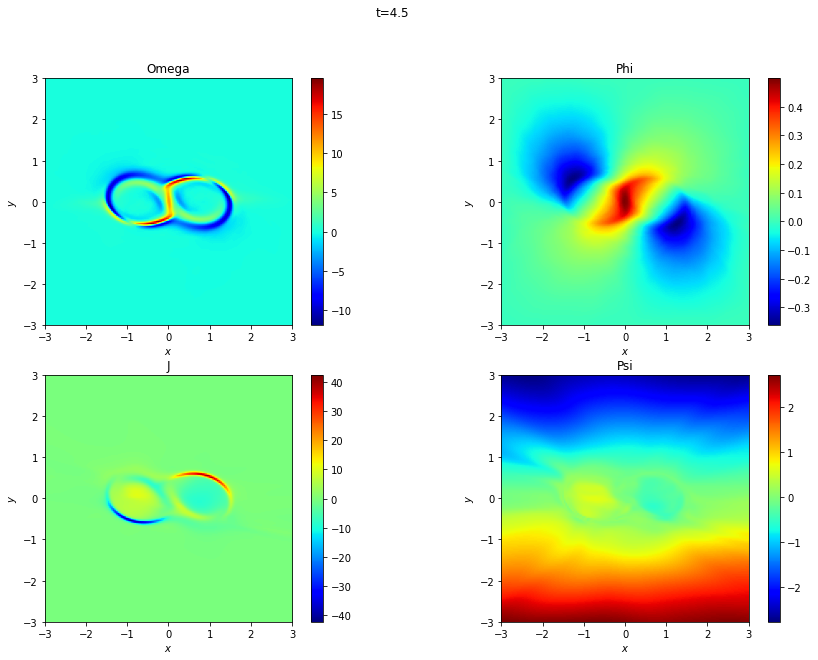

In [30]:
N = 150
t = 4.5

# compute solution using PINN
xspace = np.linspace(-3,3,N)
yspace = np.linspace(-3,3,N)
tfinal = t * np.ones(N*N)

X, Y = np.meshgrid(xspace, yspace)
Xgrid = np.vstack([tfinal.flatten(), X.flatten(), Y.flatten()]).T

hydro = model_hydro(tf.cast(Xgrid,DTYPE))
magneto = model_magneto(tf.cast(Xgrid,DTYPE))

omega, phi = hydro[:,0:1], hydro[:,1:2]
J, psi = magneto[:,0:1], magneto[:,1:2]

# reshape for plotting
omega = omega.numpy().reshape(N,N)
phi = phi.numpy().reshape(N,N)
J = J.numpy().reshape(N,N)
psi = psi.numpy().reshape(N,N)

# affichage
fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(15,10))
axs = axs.flatten()

# plot omega
axs[0].set_xlabel('$x$')
axs[0].set_ylabel('$y$')
axs[0].set_aspect('equal')
img0 = axs[0].imshow(omega, cmap='jet', origin='lower', extent=[-3,3.,-3.,3.]);
cbar0 = plt.colorbar(img0, ax=axs[0])
axs[0].set_title('Omega')

# plot phi
axs[1].set_xlabel('$x$')
axs[1].set_ylabel('$y$')
axs[1].set_aspect('equal')
img1 = axs[1].imshow(phi, cmap='jet', origin='lower', extent=[-3,3.,-3.,3.]);
cbar1 = plt.colorbar(img1, ax=axs[1])
axs[1].set_title('Phi')

# plot J
axs[2].set_xlabel('$x$')
axs[2].set_ylabel('$y$')
axs[2].set_aspect('equal')
img2 = axs[2].imshow(J, cmap='jet', origin='lower', extent=[-3,3.,-3.,3.]);
cbar2 = plt.colorbar(img2, ax=axs[2])
axs[2].set_title('J')

# plot psi
axs[3].set_xlabel('$x$')
axs[3].set_ylabel('$y$')
axs[3].set_aspect('equal')
img3 = axs[3].imshow(psi, cmap='jet', origin='lower', extent=[-3,3.,-3.,3.]);
cbar3 = plt.colorbar(img3, ax=axs[3])
axs[3].set_title('Psi')

#fig.tight_layout()
plt.suptitle('t={}'.format(t))
plt.show()

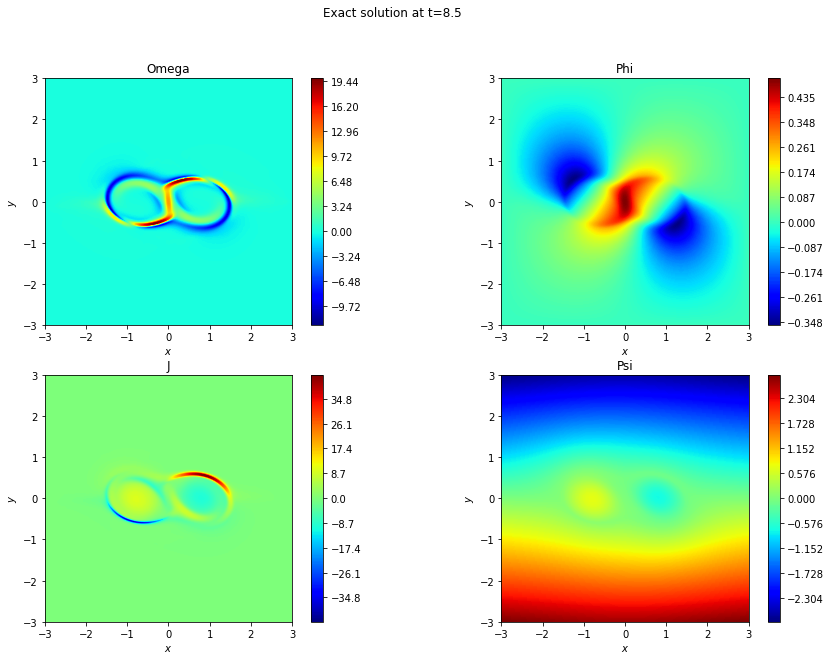

In [31]:
plot_exact_solution(850)

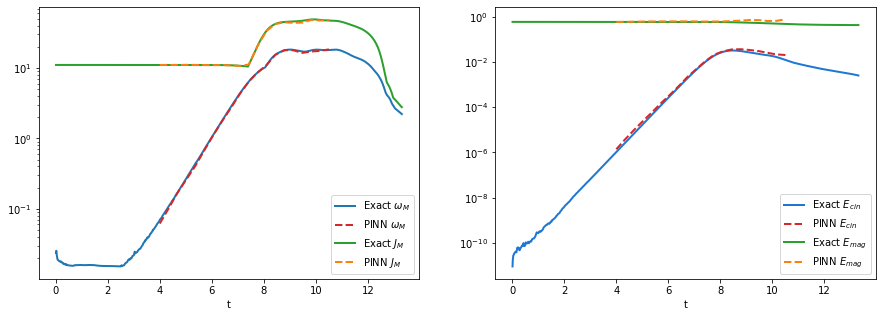

In [29]:
def plot_max_value(): 
    
    # spatial grid
    N = 150
    xspace = np.linspace(-3,3,N)
    yspace = np.linspace(-3,3,N)
    X, Y = np.meshgrid(xspace, yspace)

    omega_max = []
    J_max = []
    E_cin = []
    E_mag = []

    all_times = np.linspace(0.,6.5,20)

    for t in all_times:

        tfinal = t * np.ones(N*N)
        Xgrid = np.vstack([tfinal.flatten(), X.flatten(), Y.flatten()]).T
        Xgrid = tf.cast(Xgrid,DTYPE)

        tfinal, x, y = Xgrid[:,0:1], Xgrid[:,1:2], Xgrid[:,2:3]
        with tf.GradientTape(persistent=True) as tape:
            
            tape.watch(x)
            tape.watch(y)
            
            hydro = model_hydro(tf.stack([tfinal[:,0], x[:,0], y[:,0]], axis=1))
            magneto = model_magneto(tf.stack([tfinal[:,0], x[:,0], y[:,0]], axis=1))
            omega, phi = hydro[:,0:1], hydro[:,1:2]
            J, psi = magneto[:,0:1], magneto[:,1:2]
            
            phi_x = tape.gradient(phi, x)
            phi_y = tape.gradient(phi, y)

            psi_x = tape.gradient(psi, x)
            psi_y = tape.gradient(psi, y)

        E_cin.append( tf.reduce_mean(phi_x*phi_x + phi_y*phi_y)/2 )
        E_mag.append( tf.reduce_mean(psi_x*psi_x + psi_y*psi_y)/2 )
        del tape
        omega_max.append((tf.reduce_max(omega)-tf.reduce_min(omega))/2)
        J_max.append((tf.reduce_max(J)-tf.reduce_min(J))/2)

    data = np.genfromtxt (DATA_PATH+'histo.dat', delimiter=" ", skip_header=1)

    fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(15,5))
    axs = axs.flatten()

    all_times = [x+4. for x in all_times]
    axs[0].semilogy(data[:,0], data[:,3], 'b-', color='#1f77b4', linewidth = 2, label=r'Exact $\omega_M$')
    axs[0].semilogy(all_times, omega_max, 'r--', color='#d62728', linewidth = 2, label=r'PINN $\omega_M$')
    axs[0].semilogy(data[:,0], data[:,1], '-', color='#2ca02c', linewidth = 2, label=r'Exact $J_M$')
    axs[0].semilogy(all_times, J_max, '--', color='#ff7f0e', linewidth = 2, label=r'PINN $J_M$')
    axs[0].set_xlabel('t')
    axs[0].set_ylabel('')
    axs[0].legend()
    
    axs[1].semilogy(data[:,0], data[:,4], '-', color='#1f77d4', linewidth = 2, label=r'Exact $E_{cin}$')
    axs[1].semilogy(all_times, E_cin, '--', color='#d62728', linewidth = 2, label=r'PINN $E_{cin}$')
    axs[1].semilogy(data[:,0], data[:,6], '-', color='#2ca02c', linewidth = 2, label=r'Exact $E_{mag}$')
    axs[1].semilogy(all_times, E_mag, '--', color='#ff7f0e', linewidth = 2, label=r'PINN $E_{mag}$')
    axs[1].set_xlabel('t')
    axs[1].set_ylabel('')
    axs[1].legend()
plot_max_value()

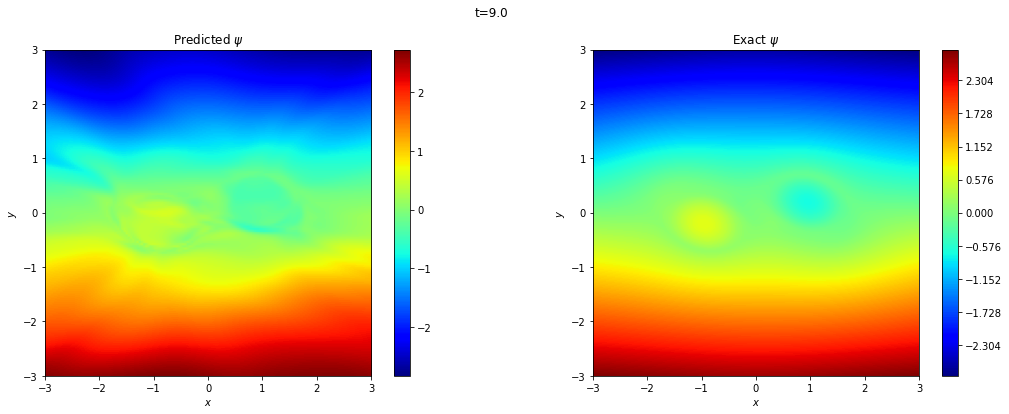

In [64]:
N = 150
t = 5
T = 900

# compute solution using PINN
xspace = np.linspace(-3,3,N)
yspace = np.linspace(-3,3,N)
tfinal = t * np.ones(N*N)

X, Y = np.meshgrid(xspace, yspace)
Xgrid = np.vstack([tfinal.flatten(), X.flatten(), Y.flatten()]).T

hydro = model_hydro(tf.cast(Xgrid,DTYPE))
magneto = model_magneto(tf.cast(Xgrid,DTYPE))

omega, phi = hydro[:,0:1], hydro[:,1:2]
J, psi = magneto[:,0:1], magneto[:,1:2]

# reshape for plotting
omega = omega.numpy().reshape(N,N)
phi = phi.numpy().reshape(N,N)
J = J.numpy().reshape(N,N)
psi = psi.numpy().reshape(N,N)


# exact solution 

# load exact solution
reader = meshio.read(DATA_PATH+'tiltpsi'+str(T)+'.vtk')
x = reader.points
triangles =  reader.cells_dict['triangle']
omega_ex = reader.point_data['champ']

# affichage
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(18,6))
axs = axs.flatten()

# plot J
axs[0].set_xlabel('$x$')
axs[0].set_ylabel('$y$')
axs[0].set_aspect('equal')
img2 = axs[0].imshow(psi, cmap='jet', origin='lower', extent=[-3,3.,-3.,3.]);
cbar2 = plt.colorbar(img2, ax=axs[0])
axs[0].set_title('Predicted $\psi$')

# plot psi
axs[1].set_xlabel('$x$')
axs[1].set_ylabel('$y$')
axs[1].set_aspect('equal')
img3  = axs[1].tricontourf(x[:,0], x[:,1], triangles, omega_ex, 800, cmap='jet');
cbar3 = plt.colorbar(img3, ax=axs[1])
axs[1].set_title('Exact $\psi$')

#fig.tight_layout()
plt.suptitle('t={}'.format(4.+t))
plt.show()